# EOD temporal waveform and fish identity (4-fish Kaden recordings)

Can the EOD waveform itself tell the four fish apart?

**EODs:** the clean set where the emitter is certain, `results/eod_assign_4fish_kaden/clean_emitter_set_71/best1000_per_fish_71.csv`:
1000 per fish, 4000 in total, from 70 recordings of 2024-02-20. Each emitter is ≥ 10 cm from every other fish, has good masks, the best
shape fit, its 2 nearest pairs are the 2 loudest, and it dominates them 2×.

**Steps** (one waveform per EOD):
1. **biggest pair**: the electrode pair with the largest peak-to-peak of the 10; its 25-sample trace from the EOD table
   (`data/4 fish/Data_4fish_2024-02-20T<video>.csv`, `electrode_<p>_time_1..25`), baseline = mean of the last 5 samples removed;
2. **interpolate + upsample**: cubic spline through the 25 samples, UP = 20 points per sample (no FFT ringing at the window edges);
3. **flip** so every EOD faces the same way: the main trough comes before the main peak (negative, then positive);
4. **align** to the upsampled positive peak (t = 0), and cut the window every EOD covers;
5. **normalize** the amplitude: peak = 1;
6. **PCA** on all 4000 normalized waveforms; **denoise** by reconstructing from the first K components;
7. colour each EOD by its fish and compare.

**Time axis:** electrodes sampled at **20 kHz** (`eod_two_layer_pipeline_clean.ipynb`, `fs=20000.0`): 1 sample = 50 µs, so the
25 samples of an EOD span 1.2 ms; after upsampling x20 the time step is 2.5 µs.

**Confound to keep in mind:** a pair records the field of a dipole-like fish, so the waveform at one pair also depends on where the fish
is and how it points relative to that pair, not only on the fish. Section 5 checks that.

In [1]:
import os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
%matplotlib inline

BASE = 'results/eod_assign_4fish_kaden'
OUT = f'{BASE}/temporal_waveform_fish_identities'; os.makedirs(OUT, exist_ok=True)
FISH = 'ABCD'
COL = {'A': '#2E9BFF', 'B': '#00D26A', 'C': '#FFC400', 'D': '#FF4F79'}   # bright, for the black spike-sorter style plots
FS, UP, N_S, K = 20000.0, 20, 25, 5   # sampling rate (Hz),                     # upsampling factor, samples per EOD, PCA components kept for denoising
EOD = 'data/4 fish/Data_4fish_2024-02-20T{t}.csv'
COLS = [f'electrode_{p}_time_{i}' for p in range(1, 11) for i in range(1, N_S + 1)]
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
S = pd.read_csv(f'{BASE}/clean_emitter_set_71/best1000_per_fish_71.csv')
print(len(S), 'EODs,', S.video.nunique(), 'recordings,', S.groupby('fish').size().to_dict())

4000 EODs, 70 recordings, {'A': 1000, 'B': 1000, 'C': 1000, 'D': 1000}


## 1. Traces of the 4000 EODs (all 10 pairs; cached after the first run)

In [2]:
CACHE = f'{OUT}/traces_best1000.npz'
if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True); TR = z['traces']; assert (z['row'] == S.row.to_numpy()).all() and (z['video'] == S.video.to_numpy()).all()
else:
    TR = np.full((len(S), 10, N_S), np.nan); t0 = time.time()
    for t, g in S.groupby('video'):
        keep = set((g.row + 1).tolist())                               # +1: the header line
        d = pd.read_csv(EOD.format(t=t), usecols=['Frame'] + COLS, skiprows=lambda i: i > 0 and i not in keep)
        assert len(d) == len(g) and (d.Frame.to_numpy() == g.sort_values('row').Frame.to_numpy()).all(), t
        TR[g.sort_values('row').index.to_numpy()] = d[COLS].to_numpy().reshape(len(d), 10, N_S)
    np.savez_compressed(CACHE, traces=TR, row=S.row.to_numpy(), video=S.video.to_numpy().astype(str))
    print(f'read in {(time.time() - t0) / 60:.1f} min')
print(TR.shape, 'NaN:', np.isnan(TR).sum())

(4000, 10, 25) NaN: 0


## 2. Biggest pair, upsample, flip, align, normalize

In [3]:
ptp = TR.max(2) - TR.min(2)
PAIR = ptp.argmax(1)                                                     # biggest pair (0-9)
print(f'biggest pair = nearest pair (by distance) for {(PAIR + 1 == S.nearest_pair).mean() * 100:.1f}% of the EODs')
X = TR[np.arange(len(S)), PAIR]                                           # (n, 25)
X = X - X[:, -5:].mean(1, keepdims=True)                                  # baseline: the last 5 samples
tf = np.arange(0, N_S - 1 + 1e-9, 1 / UP)                                 # upsampled sample times
XU = CubicSpline(np.arange(N_S), X, axis=1)(tf)                           # (n, 481)
flip = XU.argmax(1) < XU.argmin(1)                                        # peak before trough -> flip so the trough comes first
XU[flip] *= -1
pk = XU.argmax(1)                                                         # upsampled positive peak
lo, hi = pk.min(), len(tf) - 1 - pk.max()                                 # window every EOD covers
lag = np.arange(-lo, hi + 1) / UP                                         # samples relative to the peak
t_us = lag * 1e6 / FS                                                     # µs relative to the peak
W = np.stack([XU[i, pk[i] - lo: pk[i] + hi + 1] for i in range(len(S))])
amp = W[:, lo].copy(); W = W / amp[:, None]                               # peak = 1
fish = S.fish.to_numpy()
print(f'flipped {flip.mean() * 100:.1f}% of the EODs; window {t_us[0]:.0f} to {t_us[-1]:.0f} µs around the peak '
      f'({W.shape[1]} points); peak position in the raw window: {np.percentile(pk / UP, [5, 50, 95]).round(2)} samples')
pd.DataFrame({'flipped %': pd.Series(flip).groupby(fish).mean() * 100,
              'peak position (sample, median)': pd.Series(pk / UP).groupby(fish).median(),
              'biggest pair = nearest %': pd.Series(PAIR + 1 == S.nearest_pair.to_numpy()).groupby(fish).mean() * 100}).round(2)

biggest pair = nearest pair (by distance) for 78.3% of the EODs
flipped 50.0% of the EODs; window -572 to 575 µs around the peak (460 points); peak position in the raw window: [11.5 12.  12.4] samples


,flipped %,"peak position (sample, median)",biggest pair = nearest %
A,45.8,12.00,73.8
B,40.3,12.00,76.3
C,54.7,12.00,82.2
D,59.4,12.05,81.0


## 3. PCA and denoising

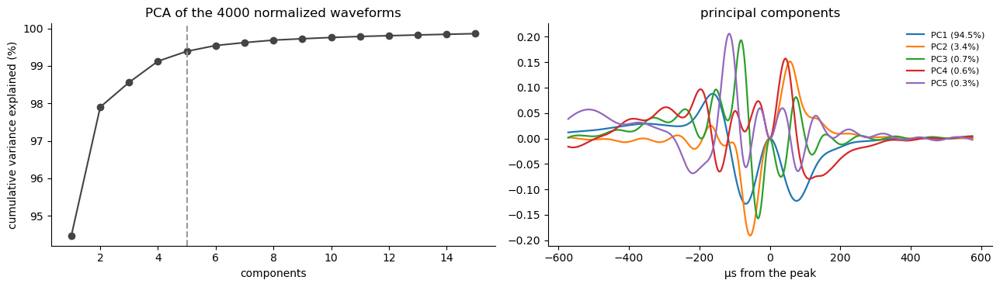

first 5 components: 99.39% of the variance


In [4]:
MU = W.mean(0); U_, SV, VT = np.linalg.svd(W - MU, full_matrices=False)
EV = SV ** 2 / (SV ** 2).sum()
PC = (W - MU) @ VT[:K].T                                                  # scores (n, K)
WD = MU + PC @ VT[:K]                                                     # denoised waveforms
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(np.arange(1, 16), np.cumsum(EV[:15]) * 100, 'o-', color='#444'); axs[0].axvline(K, color='#999', ls='--')
axs[0].set(xlabel='components', ylabel='cumulative variance explained (%)', title=f'PCA of the {len(W)} normalized waveforms')
for j in range(K): axs[1].plot(t_us, VT[j], lw=1.6, label=f'PC{j + 1} ({EV[j] * 100:.1f}%)')
axs[1].set(xlabel='µs from the peak', title='principal components'); axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(f'{OUT}/pca_components.png', dpi=110, bbox_inches='tight'); plt.show()
print(f'first {K} components: {EV[:K].sum() * 100:.2f}% of the variance')

## 4. Waveforms coloured by fish (spike-sorter style)

All 4000 denoised waveforms, one colour per fish (drawn in random order so no fish hides the others); thick lines: each fish's mean.
Right: the same per fish.

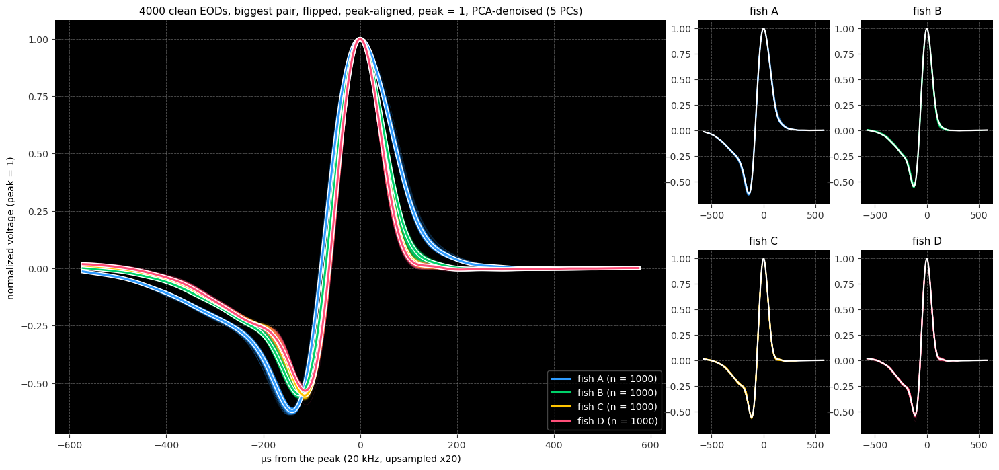

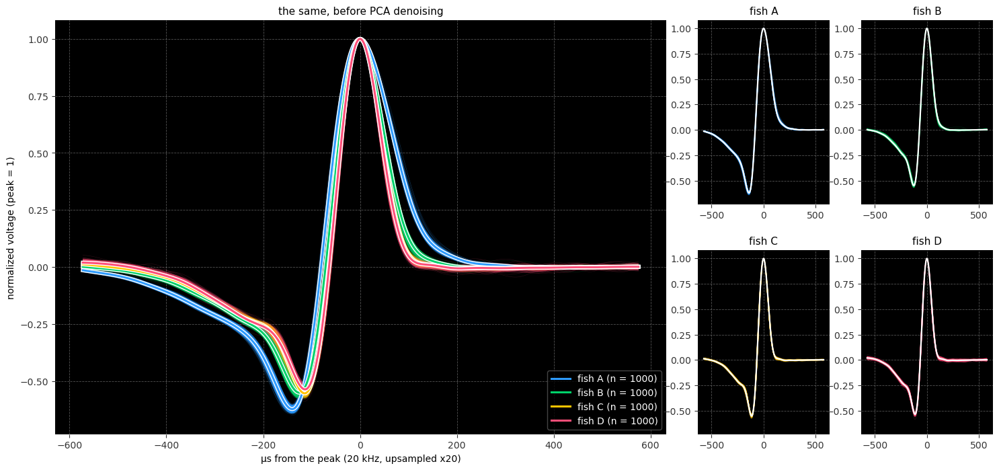

In [5]:
def sorter_axes(ax, title):
    ax.set_facecolor('black'); ax.grid(True, color='#777', ls='--', lw=0.6, alpha=0.7)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors='#333'); ax.set_title(title, fontsize=11)

def overlay(Y, fname, title):
    rng = np.random.default_rng(0); order = rng.permutation(len(Y))
    fig = plt.figure(figsize=(18, 8)); gs = fig.add_gridspec(2, 4, width_ratios=[2.2, 2.2, 1, 1], wspace=0.15, hspace=0.25)
    ax = fig.add_subplot(gs[:, :2]); sorter_axes(ax, title)
    for i in order: ax.plot(t_us, Y[i], color=COL[fish[i]], lw=0.4, alpha=0.18)
    for f in FISH:
        ax.plot(t_us, Y[fish == f].mean(0), color='white', lw=4.2); ax.plot(t_us, Y[fish == f].mean(0), color=COL[f], lw=2.2, label=f'fish {f} (n = {(fish == f).sum()})')
    ax.legend(loc='lower right', fontsize=10, facecolor='black', labelcolor='white', edgecolor='#555')
    ax.set_xlabel('µs from the peak (20 kHz, upsampled x%d)' % UP); ax.set_ylabel('normalized voltage (peak = 1)')
    for k, f in enumerate(FISH):
        a = fig.add_subplot(gs[k // 2, 2 + k % 2]); sorter_axes(a, f'fish {f}')
        for i in np.flatnonzero(fish == f)[:400]: a.plot(t_us, Y[i], color=COL[f], lw=0.4, alpha=0.2)
        a.plot(t_us, Y[fish == f].mean(0), color='white', lw=1.6); a.set_ylim(ax.get_ylim())
    fig.savefig(f'{OUT}/{fname}', dpi=110, bbox_inches='tight'); plt.show()

overlay(WD, 'waveforms_by_fish_denoised.png', f'{len(W)} clean EODs, biggest pair, flipped, peak-aligned, peak = 1, PCA-denoised ({K} PCs)')
overlay(W, 'waveforms_by_fish_raw.png', f'the same, before PCA denoising')

## 5. Can we see differences between fish?

- **means and spread**: each fish's mean waveform with ± 1 SD and the differences of the means;
- **PC space**: PC1-PC2 and PC1-PC3 coloured by fish;
- **classification**: linear discriminant on the K PC scores, trained and tested on **different recordings** (leave one recording
  out), so a fish cannot be recognised by something specific to one recording; chance = 25%;
- **confound check**: the same classifier when it may only use the biggest pair and the fish's distance to it, i.e. how much of the
  waveform difference could come from where the fish was rather than who it was.

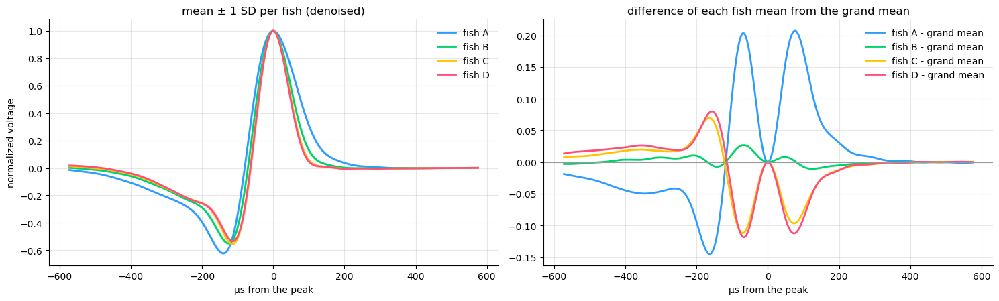

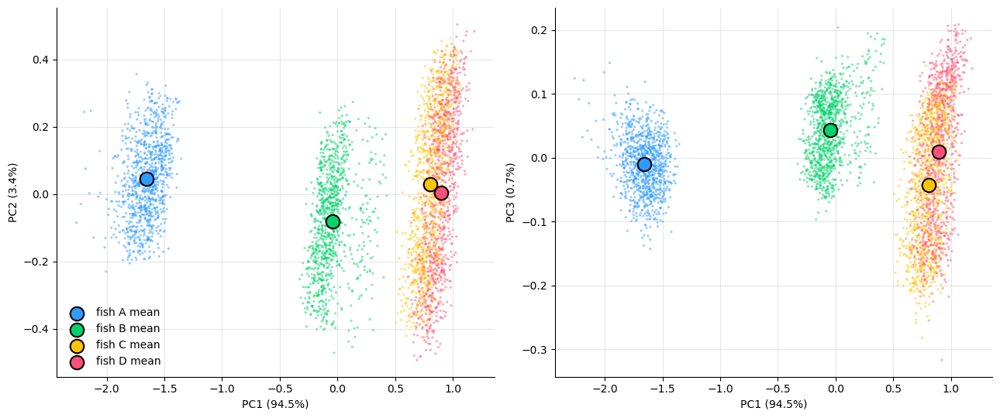

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
for f in FISH:
    m, s = WD[fish == f].mean(0), WD[fish == f].std(0)
    axs[0].plot(t_us, m, color=COL[f], lw=2, label=f'fish {f}'); axs[0].fill_between(t_us, m - s, m + s, color=COL[f], alpha=0.15)
    axs[1].plot(t_us, m - WD.mean(0), color=COL[f], lw=2, label=f'fish {f} - grand mean')
axs[0].set(xlabel='µs from the peak', ylabel='normalized voltage', title='mean ± 1 SD per fish (denoised)'); axs[0].legend(frameon=False)
axs[1].axhline(0, color='#999', lw=0.8); axs[1].set(xlabel='µs from the peak', title='difference of each fish mean from the grand mean')
axs[1].legend(frameon=False)
for a in axs: a.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(f'{OUT}/mean_waveform_per_fish.png', dpi=110, bbox_inches='tight'); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
rng = np.random.default_rng(1); order = rng.permutation(len(PC))
for a, (i, j) in zip(axs, [(0, 1), (0, 2)]):
    a.scatter(PC[order, i], PC[order, j], s=5, c=[COL[f] for f in fish[order]], alpha=0.5, linewidths=0)
    for f in FISH: a.scatter(*PC[fish == f][:, [i, j]].mean(0), s=160, color=COL[f], edgecolor='k', lw=1.5, label=f'fish {f} mean', zorder=3)
    a.set(xlabel=f'PC{i + 1} ({EV[i] * 100:.1f}%)', ylabel=f'PC{j + 1} ({EV[j] * 100:.1f}%)'); a.grid(alpha=0.3)
axs[0].legend(frameon=False)
plt.tight_layout(); fig.savefig(f'{OUT}/pc_scatter_by_fish.png', dpi=110, bbox_inches='tight'); plt.show()

In [7]:
def lda_fit(Xtr, ytr):
    mus = np.stack([Xtr[ytr == c].mean(0) for c in range(4)])
    Sw = sum(np.cov(Xtr[ytr == c].T) * ((ytr == c).sum() - 1) for c in range(4)) / (len(ytr) - 4)
    Si = np.linalg.pinv(np.atleast_2d(Sw)); pri = np.log(np.bincount(ytr, minlength=4) / len(ytr))
    return lambda Xt: (Xt @ Si @ mus.T - 0.5 * np.einsum('cj,jk,ck->c', mus, Si, mus) + pri).argmax(1)

def loro(F):
    '''leave-one-recording-out accuracy of a linear discriminant on the features F (n, d)'''
    y = np.array([FISH.index(f) for f in fish]); pred = np.full(len(y), -1); vid = S.video.to_numpy()
    for t in np.unique(vid):
        te = vid == t; pred[te] = lda_fit(F[~te], y[~te])(F[te])
    acc = (pred == y).mean() * 100
    cm = pd.crosstab(pd.Series(fish, name='true fish'), pd.Series(np.array(list(FISH))[pred], name='predicted'), normalize='index') * 100
    return acc, cm

onehot = np.eye(10)[PAIR]
feats = {f'waveform: {K} PC scores': PC, 'waveform: 10 PC scores': (W - MU) @ VT[:10].T,
         'where only: biggest pair (one-hot) + distance to it': np.c_[onehot, S.dist_nearest_cm.to_numpy()],
         f'waveform {K} PCs + where': np.c_[PC, onehot, S.dist_nearest_cm.to_numpy()]}
rows = []
for name, F in feats.items():
    acc, cm = loro(F); rows.append(dict(features=name, accuracy=acc))
    if name.startswith(f'waveform: {K}'): CM = cm
ACC = pd.DataFrame(rows); ACC.to_csv(f'{OUT}/classification_leave_one_recording_out.csv', index=False)
display(ACC.round(1).set_index('features').T)
display(CM.round(1).style.format('{:.1f}').set_caption(f'confusion (% of each true fish), waveform {K} PCs, leave one recording out'))

features,waveform: 5 PC scores,waveform: 10 PC scores,where only: biggest pair (one-hot) + distance to it,waveform 5 PCs + where
accuracy,97.6,99.8,27.8,97.7


predicted,A,B,C,D
true fish,,,,
A,100.0,0.0,0.0,0.0
B,0.0,100.0,0.0,0.0
C,0.0,0.0,95.8,4.2
D,0.0,0.0,5.4,94.6


In [8]:
# how far apart are the fish in PC space, compared with the spread within a fish? (d' along the best pair of fish means)
D = pd.DataFrame(index=list(FISH), columns=list(FISH), dtype=float)
for a in FISH:
    for b in FISH:
        if a == b: continue
        xa, xb = PC[fish == a], PC[fish == b]; w = np.linalg.pinv((np.cov(xa.T) + np.cov(xb.T)) / 2) @ (xa.mean(0) - xb.mean(0))
        pa, pb = xa @ w, xb @ w; D.loc[a, b] = abs(pa.mean() - pb.mean()) / np.sqrt((pa.var() + pb.var()) / 2)
D.round(2).style.format('{:.2f}', na_rep='').set_caption("d' between each pair of fish along their best linear direction in PC space (> ~2: well separated)")

,A,B,C,D
A,,13.47,27.25,29.62
B,13.47,,10.18,9.82
C,27.25,10.18,,3.75
D,29.62,9.82,3.75,


## 6. Variability within each fish

All EODs normalized (peak = 1) and peak-aligned as above, drawn on top of each other in their fish's colour (no mean line), with two
zooms: on the trough (-260 to -60 µs) and on the fall after the peak (20 to 220 µs). First all four fish together, then one row per
fish (same axes in every row). Spread = RMS distance of each EOD from its fish's mean waveform (normalized units, peak = 1).

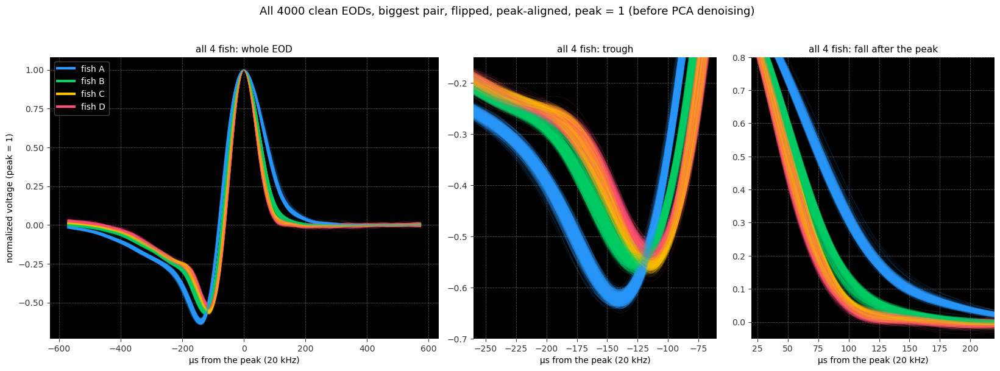

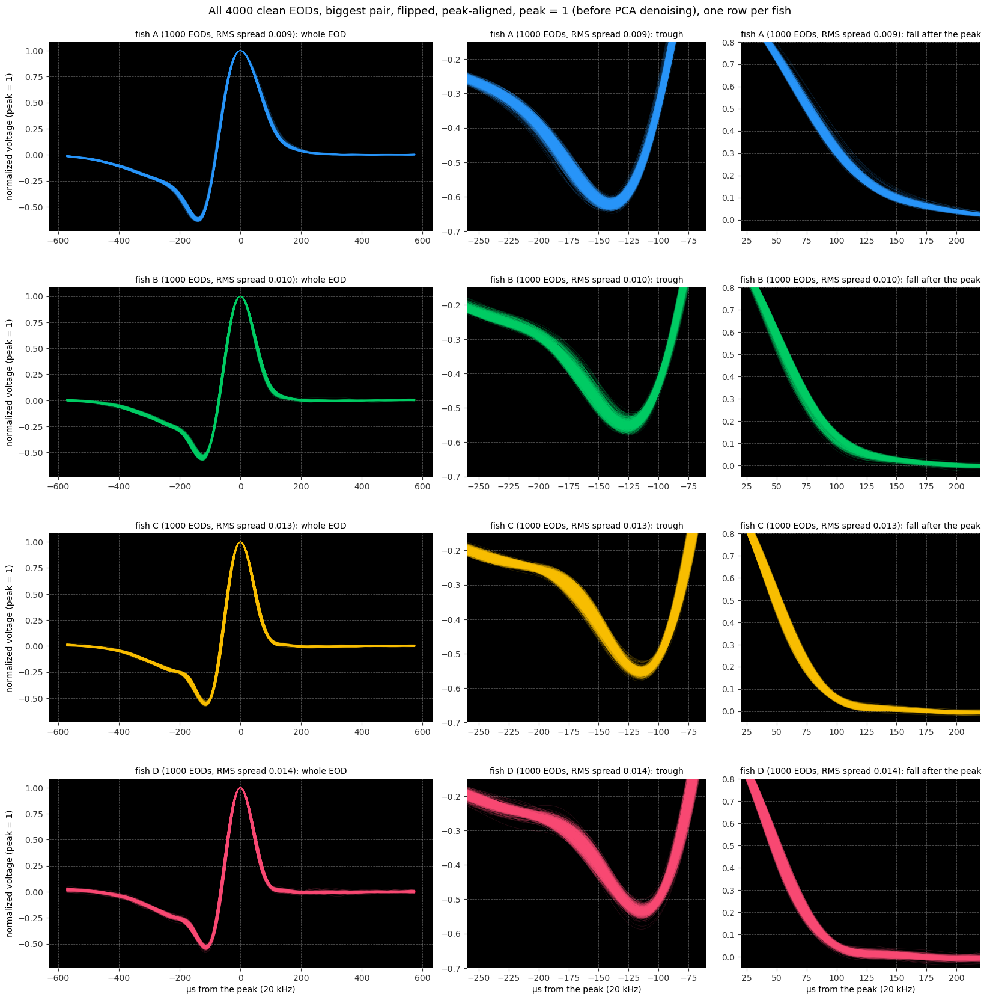

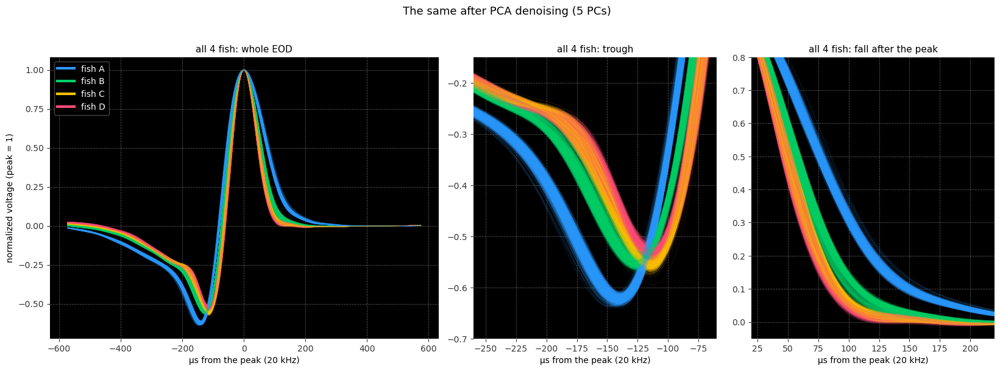

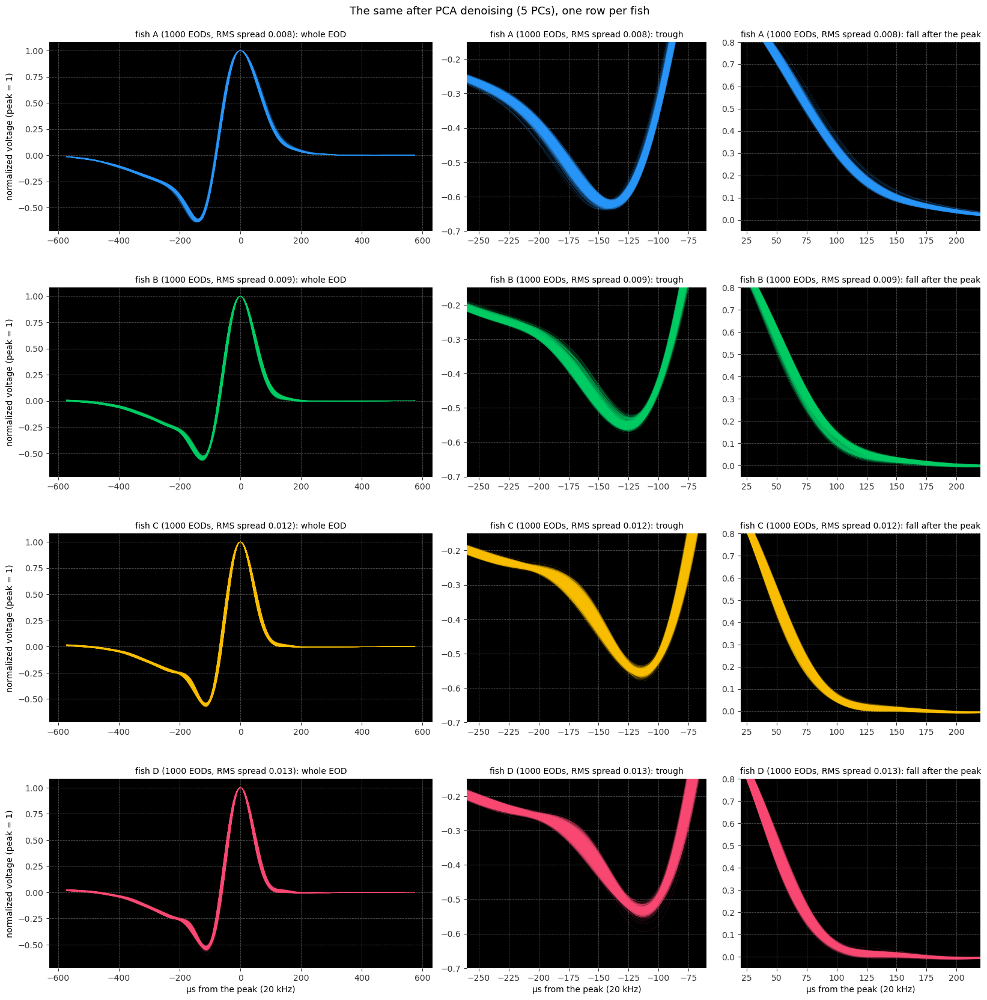

,RMS from own fish mean (raw),RMS from own fish mean (denoised),RMS from the mean of all EODs (denoised)
A,0.0089,0.0081,0.0775
B,0.0099,0.0092,0.0117
C,0.0126,0.0121,0.0395
D,0.0138,0.0129,0.0437


In [9]:
ZOOMS = [('whole EOD', None, None), ('trough', (-260, -60), (-0.70, -0.15)), ('fall after the peak', (20, 220), (-0.05, 0.80))]

def lines(a, Y, colours, lw=0.45, alpha=0.2):
    for y, c in zip(Y, colours): a.plot(t_us, y, color=c, lw=lw, alpha=alpha)

def zoom_row(axs, Y, colours, label):
    for a, (name, xl, yl) in zip(axs, ZOOMS):
        sorter_axes(a, f'{label}: {name}'); lines(a, Y, colours)
        if xl: a.set_xlim(xl); a.set_ylim(yl)

def plot_variability(Y, tag, title):
    rng = np.random.default_rng(0); order = rng.permutation(len(Y))
    fig, axs = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw=dict(width_ratios=[1.6, 1, 1], wspace=0.12))
    zoom_row(axs, Y[order], [COL[f] for f in fish[order]], 'all 4 fish')
    for f in FISH: axs[0].plot([], [], color=COL[f], lw=3, label=f'fish {f}')
    axs[0].legend(loc='upper left', fontsize=10, facecolor='black', labelcolor='white', edgecolor='#555')
    for a in axs: a.set_xlabel('µs from the peak (20 kHz)')
    axs[0].set_ylabel('normalized voltage (peak = 1)'); fig.suptitle(title, y=1.02, fontsize=13)
    fig.savefig(f'{OUT}/waveforms_all_fish_zoom_{tag}.png', dpi=110, bbox_inches='tight'); plt.show()

    fig, axs = plt.subplots(4, 3, figsize=(20, 20), gridspec_kw=dict(width_ratios=[1.6, 1, 1], wspace=0.12, hspace=0.3))
    for r, f in enumerate(FISH):
        Yf = Y[fish == f]; rms = np.sqrt(((Yf - Yf.mean(0)) ** 2).mean(1)).mean()
        zoom_row(axs[r], Yf, [COL[f]] * len(Yf), f'fish {f} ({len(Yf)} EODs, RMS spread {rms:.3f})')
        axs[r, 0].set_ylabel('normalized voltage (peak = 1)')
        for c in range(3): axs[r, c].title.set_fontsize(10)
    for a in axs[-1]: a.set_xlabel('µs from the peak (20 kHz)')
    for c in range(3):                                             # same axes in every row
        lims = [axs[r, c].get_ylim() for r in range(4)]
        for r in range(4): axs[r, c].set_ylim(min(l[0] for l in lims), max(l[1] for l in lims))
    fig.suptitle(title + ', one row per fish', y=0.91, fontsize=13)
    fig.savefig(f'{OUT}/waveforms_per_fish_zoom_{tag}.png', dpi=110, bbox_inches='tight'); plt.show()

plot_variability(W, 'raw', 'All 4000 clean EODs, biggest pair, flipped, peak-aligned, peak = 1 (before PCA denoising)')
plot_variability(WD, 'denoised', f'The same after PCA denoising ({K} PCs)')
spread = lambda Y, M: np.sqrt(((Y - M) ** 2).mean(1))
SP = pd.DataFrame({f: {'RMS from own fish mean (raw)': spread(W[fish == f], W[fish == f].mean(0)).mean(),
                       'RMS from own fish mean (denoised)': spread(WD[fish == f], WD[fish == f].mean(0)).mean(),
                       'RMS from the mean of all EODs (denoised)': spread(WD[fish == f], WD.mean(0)).mean()} for f in FISH}).T
SP.to_csv(f'{OUT}/waveform_spread_per_fish.csv'); SP.round(4)

## 7. The same analysis with another fish nearby: 0-2, 2-5, 5-10 cm

EODs: `good_mask_example_field_frames/best_lowest_L2/example_set.csv` (5 recordings, 2026-11-16): the clean-emitter rules except
isolation (good masks for all fish; the emitter has the lowest shape L2; its 2 nearest pairs are the 2 loudest with the model sign; on
the 3 loudest pairs every other fish's L2 >= 2x the emitter's), with the nearest other fish at **0-2, 2-5 or 5-10 cm**
(midline-to-midline), the **24 lowest emitter L2 per fish and bin** (fish B at 0-2 cm: 12), >= 100 frames apart.

Exactly the same steps (biggest pair, cubic spline x20, flip, align to the peak, peak = 1). The waveforms are projected onto the PCA
of the 4000 isolated EODs (sections 3-5), denoised with its first K components, and classified by the discriminant trained on those
4000 (5 PC scores): does the waveform still tell the fish apart when another fish is close?

In [10]:
EX = pd.read_csv(f'{BASE}/good_mask_example_field_frames/best_lowest_L2/example_set.csv')
BINS = ['0-2 cm', '2-5 cm', '5-10 cm']
CACHE2 = f'{OUT}/traces_distance_bins_best_lowest_L2.npz'
if os.path.exists(CACHE2):
    z = np.load(CACHE2, allow_pickle=True); TR2 = z['traces']; assert (z['row'] == EX.row.to_numpy()).all()
else:
    TR2 = np.full((len(EX), 10, N_S), np.nan)
    for t, g in EX.groupby('video'):
        g = g.sort_values('row'); keep = set((g.row + 1).tolist())
        d = pd.read_csv(EOD.format(t=t), usecols=['Frame'] + COLS, skiprows=lambda i: i > 0 and i not in keep)
        d = d.drop_duplicates()  # a row can be listed once per bin; the read keeps one line per row
        assert len(d) == g.row.nunique() and (d.Frame.to_numpy() == g.drop_duplicates('row').Frame.to_numpy()).all(), t
        tr = dict(zip(g.drop_duplicates('row').row, d[COLS].to_numpy().reshape(len(d), 10, N_S)))
        TR2[g.index.to_numpy()] = np.stack([tr[r] for r in g.row])
    np.savez_compressed(CACHE2, traces=TR2, row=EX.row.to_numpy(), video=EX.video.to_numpy().astype(str))

def prep(T):
    '''the steps of section 2 on traces (n, 10, 25), cut to the window of the 4000 isolated EODs: (W, pair, flipped, ok)'''
    pair = (T.max(2) - T.min(2)).argmax(1); Xb = T[np.arange(len(T)), pair]
    Xb = Xb - Xb[:, -5:].mean(1, keepdims=True)
    XUb = CubicSpline(np.arange(N_S), Xb, axis=1)(tf)
    fl = XUb.argmax(1) < XUb.argmin(1); XUb[fl] *= -1
    pkb = XUb.argmax(1); ok = (pkb - lo >= 0) & (pkb + hi < XUb.shape[1])
    Wb = np.full((len(T), lo + hi + 1), np.nan)
    for i in np.flatnonzero(ok): Wb[i] = XUb[i, pkb[i] - lo: pkb[i] + hi + 1]
    return Wb / Wb[:, [lo]], pair, fl, ok

W2, PAIR2, FLIP2, OK2 = prep(TR2)
fish2, bin2 = EX.fish.to_numpy(), EX.gap_bin.to_numpy()
PC2 = (W2 - MU) @ VT[:K].T; WD2 = MU + PC2 @ VT[:K]
print(f'{OK2.sum()} / {len(EX)} EODs fit the window; flipped {FLIP2.mean() * 100:.0f}%; '
      f'biggest pair = nearest pair for {(PAIR2 + 1 == EX.nearest_pair.to_numpy()).mean() * 100:.0f}%')
pd.crosstab(EX.fish, EX.gap_bin)

273 / 276 EODs fit the window; flipped 57%; biggest pair = nearest pair for 70%


gap_bin,0-2 cm,2-5 cm,5-10 cm
fish,,,
A,24,24,24
B,12,24,24
C,24,24,24
D,24,24,24


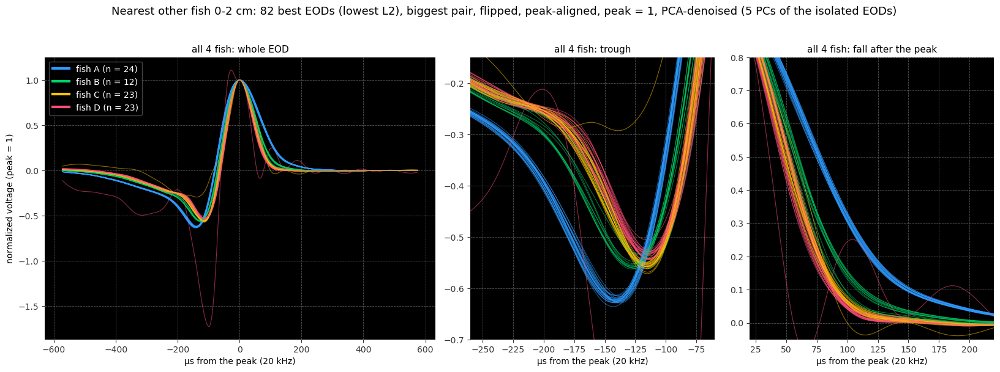

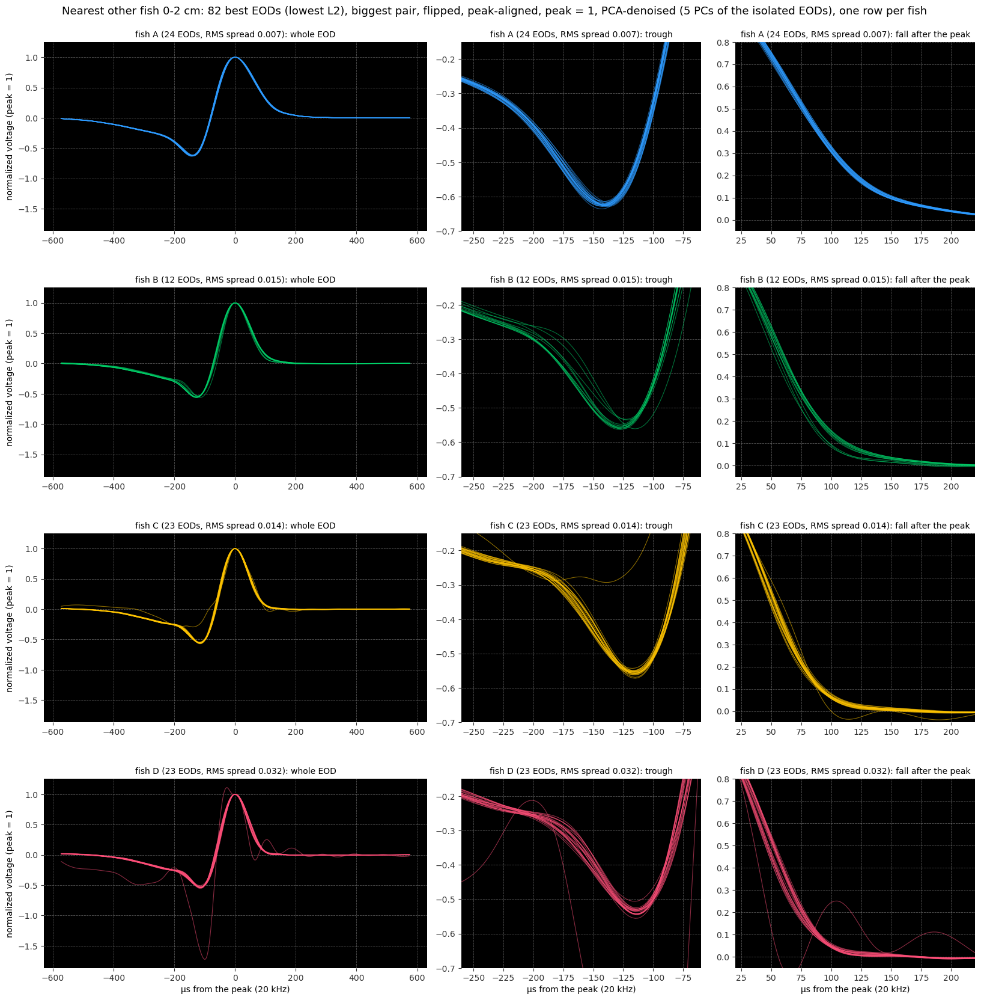

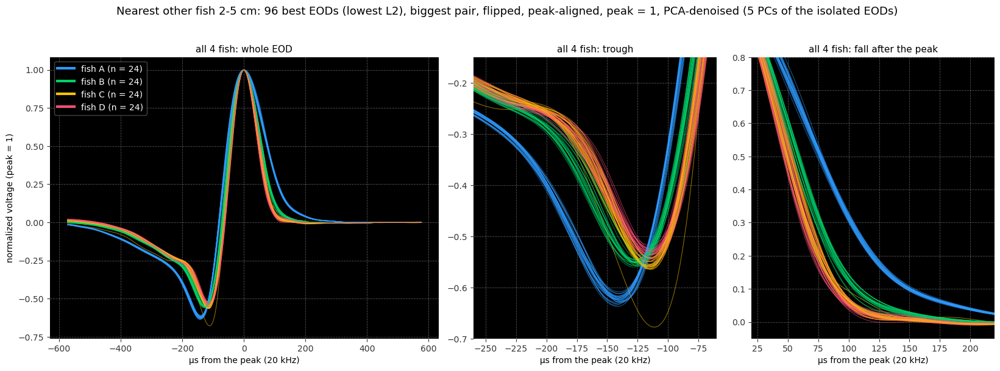

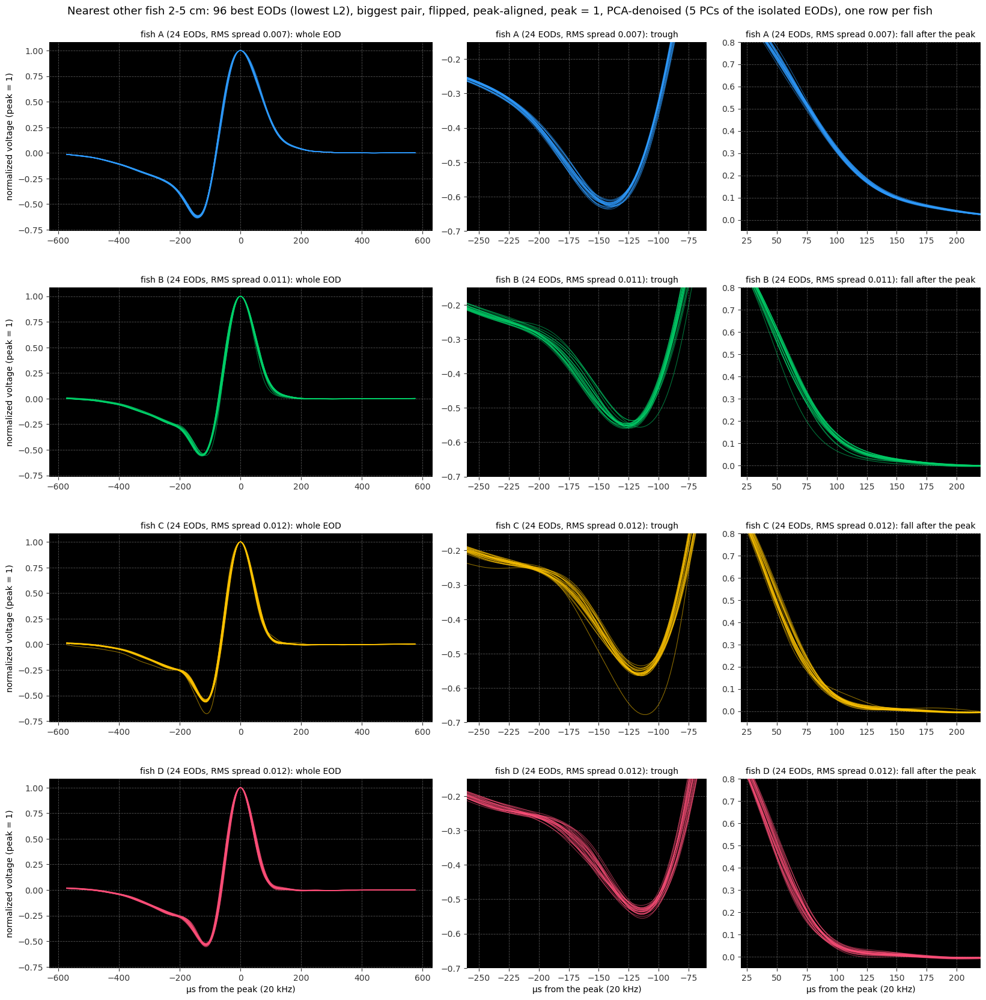

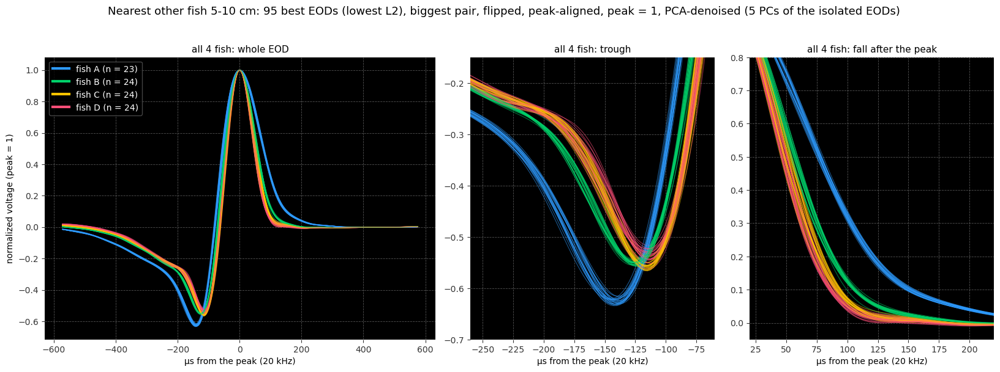

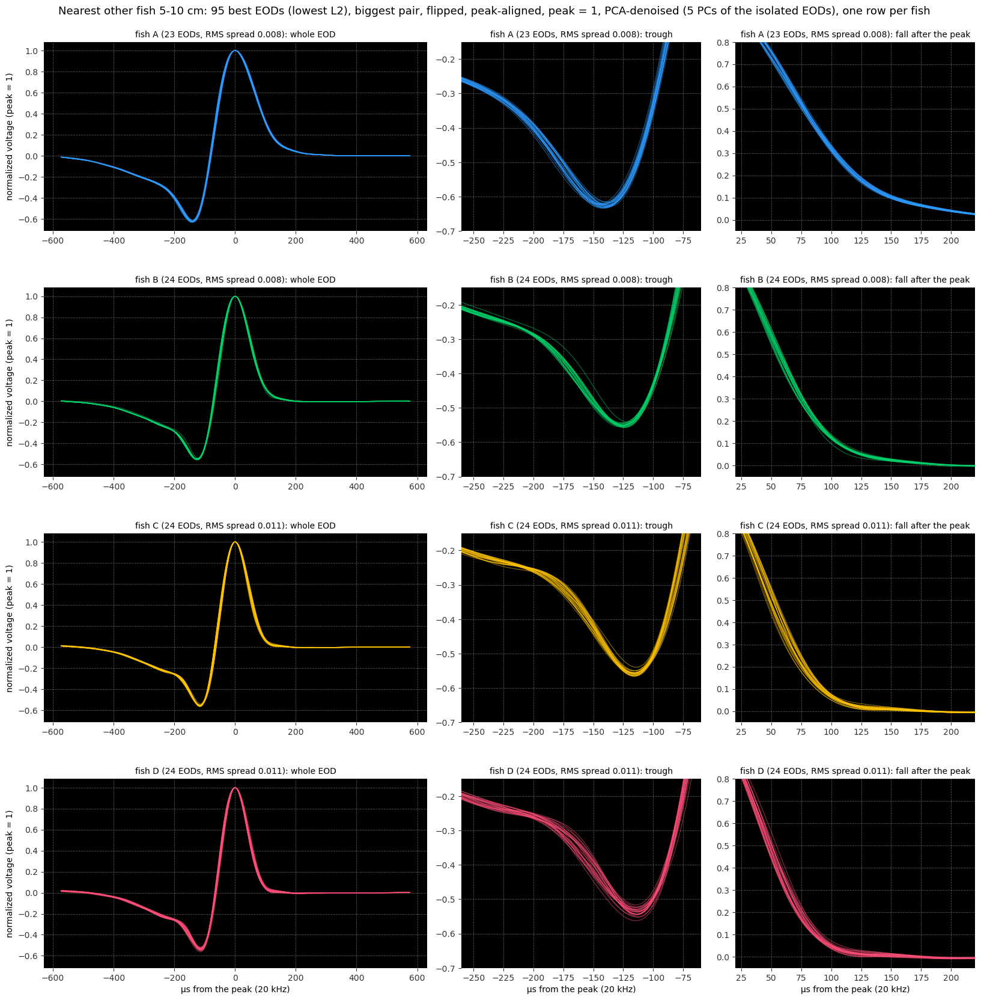

In [11]:
def plot_variability_bin(Y, fl, tag, title, lw=0.8, alpha=0.55):
    rng = np.random.default_rng(0); order = rng.permutation(len(Y))
    fig, axs = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw=dict(width_ratios=[1.6, 1, 1], wspace=0.12))
    for a, (name, xl, yl) in zip(axs, ZOOMS):
        sorter_axes(a, f'all 4 fish: {name}')
        for i in order: a.plot(t_us, Y[i], color=COL[fl[i]], lw=lw, alpha=alpha)
        if xl: a.set_xlim(xl); a.set_ylim(yl)
        a.set_xlabel('µs from the peak (20 kHz)')
    for f in FISH: axs[0].plot([], [], color=COL[f], lw=3, label=f'fish {f} (n = {(fl == f).sum()})')
    axs[0].legend(loc='upper left', fontsize=10, facecolor='black', labelcolor='white', edgecolor='#555')
    axs[0].set_ylabel('normalized voltage (peak = 1)'); fig.suptitle(title, y=1.02, fontsize=13)
    fig.savefig(f'{OUT}/waveforms_all_fish_zoom_{tag}.png', dpi=110, bbox_inches='tight'); plt.show()
    fig, axs = plt.subplots(4, 3, figsize=(20, 20), gridspec_kw=dict(width_ratios=[1.6, 1, 1], wspace=0.12, hspace=0.3))
    for r, f in enumerate(FISH):
        Yf = Y[fl == f]; rms = np.sqrt(((Yf - Yf.mean(0)) ** 2).mean(1)).mean()
        for a, (name, xl, yl) in zip(axs[r], ZOOMS):
            sorter_axes(a, f'fish {f} ({len(Yf)} EODs, RMS spread {rms:.3f}): {name}'); a.title.set_fontsize(10)
            for y in Yf: a.plot(t_us, y, color=COL[f], lw=lw, alpha=alpha)
            if xl: a.set_xlim(xl); a.set_ylim(yl)
        axs[r, 0].set_ylabel('normalized voltage (peak = 1)')
    for c in range(3):
        lims = [axs[r, c].get_ylim() for r in range(4)]
        for r in range(4): axs[r, c].set_ylim(min(l[0] for l in lims), max(l[1] for l in lims))
    for a in axs[-1]: a.set_xlabel('µs from the peak (20 kHz)')
    fig.suptitle(title + ', one row per fish', y=0.91, fontsize=13)
    fig.savefig(f'{OUT}/waveforms_per_fish_zoom_{tag}.png', dpi=110, bbox_inches='tight'); plt.show()

for b in BINS:
    k = (bin2 == b) & OK2; tag = 'nearest_fish_' + b.replace(' ', '').replace('-', '_')
    plot_variability_bin(WD2[k], fish2[k], f'{tag}_denoised', f'Nearest other fish {b}: {k.sum()} best EODs (lowest L2), '
                         f'biggest pair, flipped, peak-aligned, peak = 1, PCA-denoised ({K} PCs of the isolated EODs)')

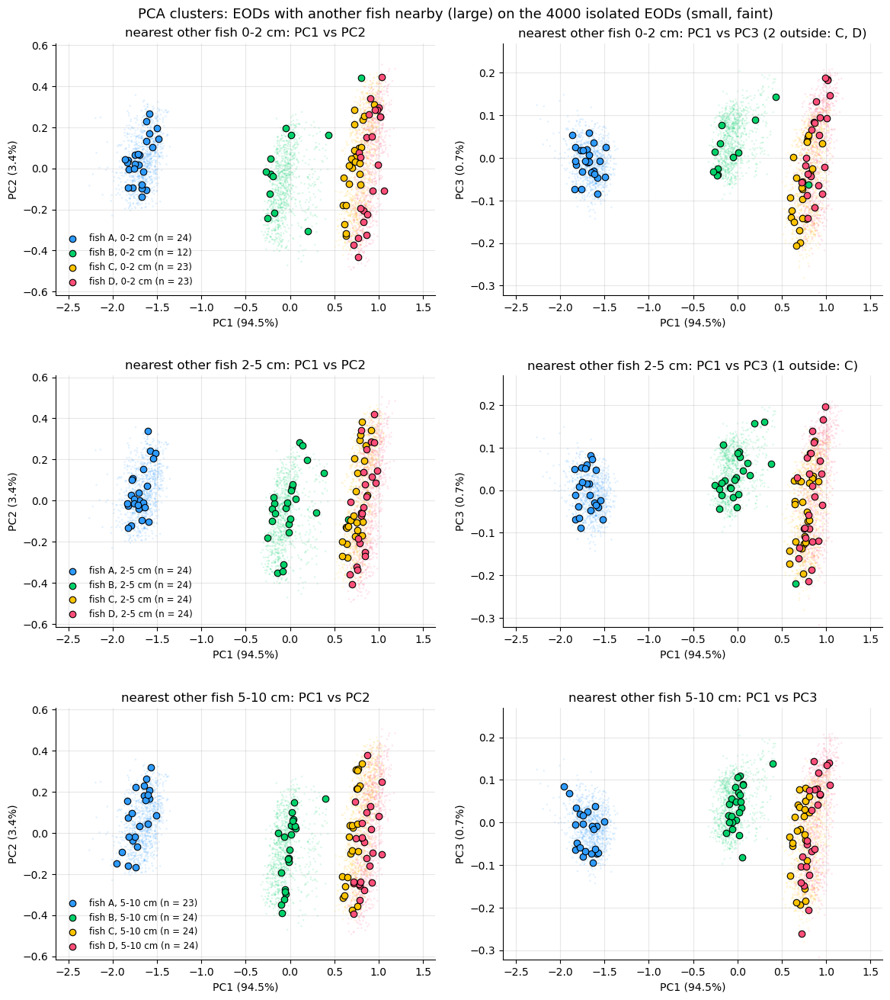

,EODs,accuracy,fish A,fish B,fish C,fish D
bin,,,,,,
0-2 cm,82.0,92.7,100.0,91.7,95.7,82.6
2-5 cm,96.0,94.8,100.0,95.8,95.8,87.5
5-10 cm,95.0,93.7,100.0,100.0,95.8,79.2
all,273.0,93.8,100.0,96.7,95.8,83.1


EODs  RMS spread from own mean  RMS from the isolated fish mean
0-2 cm  A  24.0                    0.0072                           0.0075
        B  12.0                    0.0154                           0.0154
        C  23.0                    0.0142                           0.0143
        D  23.0                    0.0316                           0.0269
2-5 cm  A  24.0                    0.0070                           0.0075
        B  24.0                    0.0110                           0.0112
        C  24.0                    0.0124                           0.0129
        D  24.0                    0.0123                           0.0128
5-10 cm A  23.0                    0.0085                           0.0090
        B  24.0                    0.0083                           0.0086
        C  24.0                    0.0112                           0.0123
        D  24.0                    0.0111                           0.0119

In [12]:
# PCA clusters: the bins' EODs (large, black edge) on the 4000 isolated EODs (small, faint), in the PC space of the isolated EODs
fig, axs = plt.subplots(len(BINS), 2, figsize=(14, 5.2 * len(BINS)), gridspec_kw=dict(hspace=0.32, wspace=0.18))
rng = np.random.default_rng(1); order = rng.permutation(len(PC))
for r, b in enumerate(BINS):
    k = (bin2 == b) & OK2
    for a, (i, j) in zip(axs[r], [(0, 1), (0, 2)]):
        a.scatter(PC[order, i], PC[order, j], s=3, c=[COL[f] for f in fish[order]], alpha=0.15, linewidths=0)
        for f in FISH:
            m = k & (fish2 == f)
            a.scatter(PC2[m, i], PC2[m, j], s=38, color=COL[f], edgecolor='k', lw=0.8, label=f'fish {f}, {b} (n = {m.sum()})', zorder=3)
        lim = [np.percentile(PC[:, q], [0.1, 99.9]) for q in (i, j)]; pad = [0.15 * (l[1] - l[0]) for l in lim]
        a.set_xlim(lim[0][0] - pad[0], lim[0][1] + pad[0]); a.set_ylim(lim[1][0] - pad[1], lim[1][1] + pad[1])
        out = k & ((PC2[:, i] < a.get_xlim()[0]) | (PC2[:, i] > a.get_xlim()[1]) | (PC2[:, j] < a.get_ylim()[0]) | (PC2[:, j] > a.get_ylim()[1]))
        a.set(xlabel=f'PC{i + 1} ({EV[i] * 100:.1f}%)', ylabel=f'PC{j + 1} ({EV[j] * 100:.1f}%)',
              title=f'nearest other fish {b}: PC{i + 1} vs PC{j + 1}' + (f' ({out.sum()} outside: ' + ', '.join(fish2[out]) + ')' if out.any() else ''))
        a.grid(alpha=0.3)
    axs[r, 0].legend(frameon=False, fontsize=8.5, loc='lower left')
fig.suptitle('PCA clusters: EODs with another fish nearby (large) on the 4000 isolated EODs (small, faint)', y=0.91, fontsize=13)
fig.savefig(f'{OUT}/pc_scatter_by_fish_distance_bins.png', dpi=110, bbox_inches='tight'); plt.show()

# classify them with the discriminant trained on the 4000 isolated EODs (5 PC scores)
clf = lda_fit(PC, np.array([FISH.index(f) for f in fish]))
pred2 = np.full(len(EX), '', object); pred2[OK2] = np.array(list(FISH))[clf(PC2[OK2])]
rows = []
for b in BINS + ['all']:
    k = OK2 & ((bin2 == b) if b != 'all' else True)
    rows.append(dict(bin=b, EODs=int(k.sum()), accuracy=(pred2[k] == fish2[k]).mean() * 100,
                     **{f'fish {f}': (pred2[k & (fish2 == f)] == f).mean() * 100 for f in FISH}))
ACC2 = pd.DataFrame(rows); ACC2.to_csv(f'{OUT}/classification_distance_bins.csv', index=False)
display(ACC2.round(1).set_index('bin').style.format('{:.1f}').set_caption('% correctly identified by the waveform discriminant trained on the isolated EODs'))
SP2 = pd.DataFrame({(b, f): {'EODs': int(((bin2 == b) & OK2 & (fish2 == f)).sum()),
                             'RMS spread from own mean': np.sqrt(((WD2[(bin2 == b) & OK2 & (fish2 == f)] - WD2[(bin2 == b) & OK2 & (fish2 == f)].mean(0)) ** 2).mean(1)).mean(),
                             'RMS from the isolated fish mean': np.sqrt(((WD2[(bin2 == b) & OK2 & (fish2 == f)] - WD[fish == f].mean(0)) ** 2).mean(1)).mean()}
                    for b in BINS for f in FISH}).T
SP2.to_csv(f'{OUT}/waveform_spread_distance_bins.csv'); SP2.round(4)

## 8. PCA in 3 dimensions: do C and D separate?

Top: the 4000 isolated EODs in PC1-PC2-PC3, seen from three angles. PC1 (EOD width) splits A, B and C+D; C and D overlap on it.
Bottom: only C and D, on the 3 of the first 10 components that separate them best (largest d' = |mean C - mean D| / pooled SD),
isolated EODs (small) and the EODs with another fish within 10 cm (large, black edge).

PC,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
variance %,94.474,3.428,0.658,0.565,0.263,0.155,0.078,0.066,0.037,0.033
C vs D d',0.837,0.109,0.520,0.359,2.569,0.555,1.035,0.132,0.214,0.673


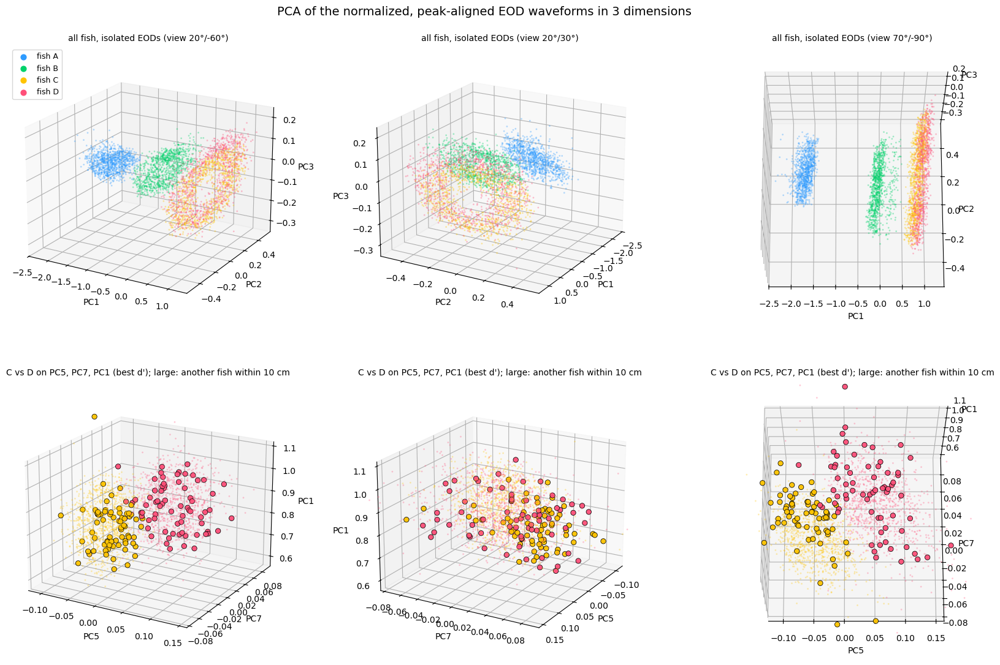

PC1-3                     69.0
best 3 (PC5, PC7, PC1)    96.8
PC1-5                     97.2
PC1-10                    99.6
Name: C vs D accuracy % (leave one recording out), dtype: float64

In [13]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
PC10 = (W - MU) @ VT[:10].T; PC10b = (W2 - MU) @ VT[:10].T
cC, cD = fish == 'C', fish == 'D'
dprime = np.abs(PC10[cC].mean(0) - PC10[cD].mean(0)) / np.sqrt((PC10[cC].var(0) + PC10[cD].var(0)) / 2)
best3 = np.argsort(-dprime)[:3]
display(pd.DataFrame({'PC': [f'PC{j + 1}' for j in range(10)], 'variance %': EV[:10] * 100, "C vs D d'": dprime}).round(3).set_index('PC').T)

def scatter3(ax, P, cols, s, alpha, edge=None):
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=s, c=cols, alpha=alpha, linewidths=0.6 if edge else 0, edgecolors=edge, depthshade=False)

VIEWS = [(20, -60), (20, 30), (70, -90)]
rng = np.random.default_rng(2); order = rng.permutation(len(W))
fig = plt.figure(figsize=(21, 13))
for c, (el, az) in enumerate(VIEWS):
    ax = fig.add_subplot(2, 3, c + 1, projection='3d')
    scatter3(ax, PC10[order][:, :3], [COL[f] for f in fish[order]], 4, 0.35)
    ax.view_init(el, az); ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3'); ax.set_title(f'all fish, isolated EODs (view {el}°/{az}°)', fontsize=10)
    if c == 0:
        for f in FISH: ax.scatter([], [], [], color=COL[f], s=40, label=f'fish {f}')
        ax.legend(loc='upper left', fontsize=9)
k2 = OK2 & np.isin(fish2, ['C', 'D'])
for c, (el, az) in enumerate(VIEWS):
    ax = fig.add_subplot(2, 3, 4 + c, projection='3d')
    m = cC | cD
    scatter3(ax, PC10[order][m[order]][:, best3], [COL[f] for f in fish[order][m[order]]], 4, 0.3)
    scatter3(ax, PC10b[k2][:, best3], [COL[f] for f in fish2[k2]], 36, 0.95, edge='k')
    ax.view_init(el, az); ax.set(xlabel=f'PC{best3[0] + 1}', ylabel=f'PC{best3[1] + 1}', zlabel=f'PC{best3[2] + 1}')
    ax.set_title(f"C vs D on PC{best3[0] + 1}, PC{best3[1] + 1}, PC{best3[2] + 1} (best d'); large: another fish within 10 cm", fontsize=10)
    lim = [np.percentile(PC10[m][:, j], [0.5, 99.5]) for j in best3]
    ax.set_xlim(*lim[0]); ax.set_ylim(*lim[1]); ax.set_zlim(*lim[2])
fig.suptitle('PCA of the normalized, peak-aligned EOD waveforms in 3 dimensions', y=0.93, fontsize=14)
fig.savefig(f'{OUT}/pca_3d.png', dpi=110, bbox_inches='tight'); plt.show()

# how separable are C and D using all 10 PCs vs the 3 best (leave one recording out, linear discriminant)
y = (fish[cC | cD] == 'D').astype(int); vid = S.video.to_numpy()[cC | cD]
def cd_acc(F):
    pred = np.full(len(y), -1)
    for t in np.unique(vid):
        te = vid == t; mus = np.stack([F[~te][y[~te] == c].mean(0) for c in (0, 1)])
        Sw = (np.cov(F[~te][y[~te] == 0].T) + np.cov(F[~te][y[~te] == 1].T)) / 2; Si = np.linalg.pinv(np.atleast_2d(Sw))
        sc = F[te] @ Si @ mus.T - 0.5 * np.einsum('cj,jk,ck->c', mus, Si, mus); pred[te] = sc.argmax(1)
    return (pred == y).mean() * 100
pd.Series({'PC1-3': cd_acc(PC10[cC | cD][:, :3]), f'best 3 (PC{best3[0] + 1}, PC{best3[1] + 1}, PC{best3[2] + 1})': cd_acc(PC10[cC | cD][:, best3]),
           'PC1-5': cd_acc(PC10[cC | cD][:, :5]), 'PC1-10': cd_acc(PC10[cC | cD])}, name='C vs D accuracy % (leave one recording out)').round(1)

## 9. 10,000 random EODs, fish unknown

10,000 EODs drawn uniformly at random from **all** detected EODs of the 71 recordings (no clean-set rules, no fish label), run through
exactly the same steps (biggest pair, cubic spline x20, flip, align to the peak, peak = 1) and projected onto the PCs of the 4000 isolated
EODs. Shown first without any label (grey) on top of the isolated clusters, then coloured by
- the **waveform classifier** (linear discriminant on 10 PC scores, trained on the 4000 isolated EODs), and
- the **voltage-rule assignment** of the numerical model (interior 4, cluster run), for comparison.

How many fall inside a fish's cluster: Mahalanobis distance (10 PCs) to the nearest fish's isolated cluster below the 99% level of a
chi-square with 10 degrees of freedom. Random EODs include far, weak and overlapping EODs, so some fall between or outside the clusters.

In [14]:
NR, SEED_R = 10000, 7
CACHE3 = f'{OUT}/traces_random_{NR}.npz'
if os.path.exists(CACHE3):
    z = np.load(CACHE3, allow_pickle=True); RND = pd.DataFrame({'video': z['video'].astype(str), 'row': z['row']}); TR3 = z['traces']
else:
    n_per = {t: len(np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4/Voltage_prediction_4fish_2024-02-20T{t}.npz')['frames']) for t in sorted(
        v[-12:-4] for v in os.listdir(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4') if v.startswith('Voltage_prediction_4fish_2024-02-20T') and v.endswith('.npz'))}
    allv = np.repeat(list(n_per), list(n_per.values())); allr = np.concatenate([np.arange(n) for n in n_per.values()])
    pick = np.sort(np.random.default_rng(SEED_R).choice(len(allv), NR, replace=False))
    RND = pd.DataFrame({'video': allv[pick], 'row': allr[pick]}); TR3 = np.full((NR, 10, N_S), np.nan); t0 = time.time()
    for t, g in RND.groupby('video'):
        keep = set((g.row + 1).tolist())
        d = pd.read_csv(EOD.format(t=t), usecols=COLS, skiprows=lambda i: i > 0 and i not in keep)
        assert len(d) == len(g), t
        TR3[g.index.to_numpy()] = d[COLS].to_numpy().reshape(len(d), 10, N_S)
    np.savez_compressed(CACHE3, traces=TR3, row=RND.row.to_numpy(), video=RND.video.to_numpy().astype(str))
    print(f'read {NR} EODs from {RND.video.nunique()} recordings in {(time.time() - t0) / 60:.1f} min')
W3, PAIR3, FLIP3, OK3 = prep(TR3)
PC3_10 = (W3 - MU) @ VT[:10].T; WD3 = MU + PC3_10[:, :K] @ VT[:K]
rmax3 = np.abs(TR3).max((1, 2))
# voltage-rule pick of the numerical model (interior 4) for these EODs
vp = np.full(NR, '', object)
for t, g in RND.groupby('video'):
    pv = np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4/Voltage_prediction_4fish_2024-02-20T{t}.npz')['pick_voltage']; vp[g.index.to_numpy()] = pv[g.row.to_numpy()]
vp = vp.astype(str)
print(f'{OK3.sum()} / {NR} fit the window; peak amplitude on the biggest pair: median {np.median(rmax3):.3f} V '
      f'(isolated clean set: {np.median(np.abs(TR).max((1, 2))):.3f} V)')

read 10000 EODs from 71 recordings in 0.9 min


9959 / 10000 fit the window; peak amplitude on the biggest pair: median 0.061 V (isolated clean set: 0.112 V)


In [15]:
# classifier (10 PCs) and distance to the clusters
y_iso = np.array([FISH.index(f) for f in fish])
clf10 = lda_fit(PC10, y_iso)
pred3 = np.full(NR, '', object); pred3[OK3] = np.array(list(FISH))[clf10(PC3_10[OK3])]
from scipy.stats import chi2
mah = np.full((NR, 4), np.inf)
for c, f in enumerate(FISH):
    Xf = PC10[fish == f]; mu_f = Xf.mean(0); Si = np.linalg.inv(np.cov(Xf.T))
    dd = PC3_10[OK3] - mu_f; mah[OK3, c] = np.sqrt(np.einsum('ij,jk,ik->i', dd, Si, dd))
inside = mah.min(1) < np.sqrt(chi2.ppf(0.99, 10)); nearest = np.array(list(FISH))[mah.argmin(1)]
print(f'inside a fish cluster (99%, 10 PCs): {inside.sum()} / {OK3.sum()} ({inside.sum() / OK3.sum() * 100:.1f}%)')
display(pd.DataFrame({'all random EODs': pd.Series(pred3[OK3]).value_counts(normalize=True) * 100,
                      'inside a cluster': pd.Series(nearest[inside]).value_counts(normalize=True) * 100,
                      'voltage rule (numerical, int 4)': pd.Series(vp[vp != '']).value_counts(normalize=True) * 100}).reindex(list(FISH)).round(1)
        .style.format('{:.1f}').set_caption('% of the random EODs per fish'))
both = OK3 & (vp != '')
agree = pd.DataFrame({'EODs': [both.sum(), (both & inside).sum()],
                      'waveform classifier = voltage rule %': [(pred3[both] == vp[both]).mean() * 100, (pred3[both & inside] == vp[both & inside]).mean() * 100]},
                     index=['all random EODs with a voltage pick', 'only those inside a cluster'])
display(agree.round(1))
pd.crosstab(pd.Series(vp[both & inside], name='voltage rule'), pd.Series(pred3[both & inside], name='waveform classifier'))

inside a fish cluster (99%, 10 PCs): 6322 / 9959 (63.5%)


,all random EODs,inside a cluster,"voltage rule (numerical, int 4)"
A,28.8,32.3,28.9
B,17.8,22.5,18.0
C,31.5,27.3,28.2
D,21.9,17.9,24.9


,EODs,waveform classifier = voltage rule %
all random EODs with a voltage pick,9959,91.2
only those inside a cluster,6322,95.1


waveform classifier,A,B,C,D
voltage rule,,,,
A,2015,1,12,33
B,3,1405,4,36
C,13,5,1716,104
D,13,12,74,876


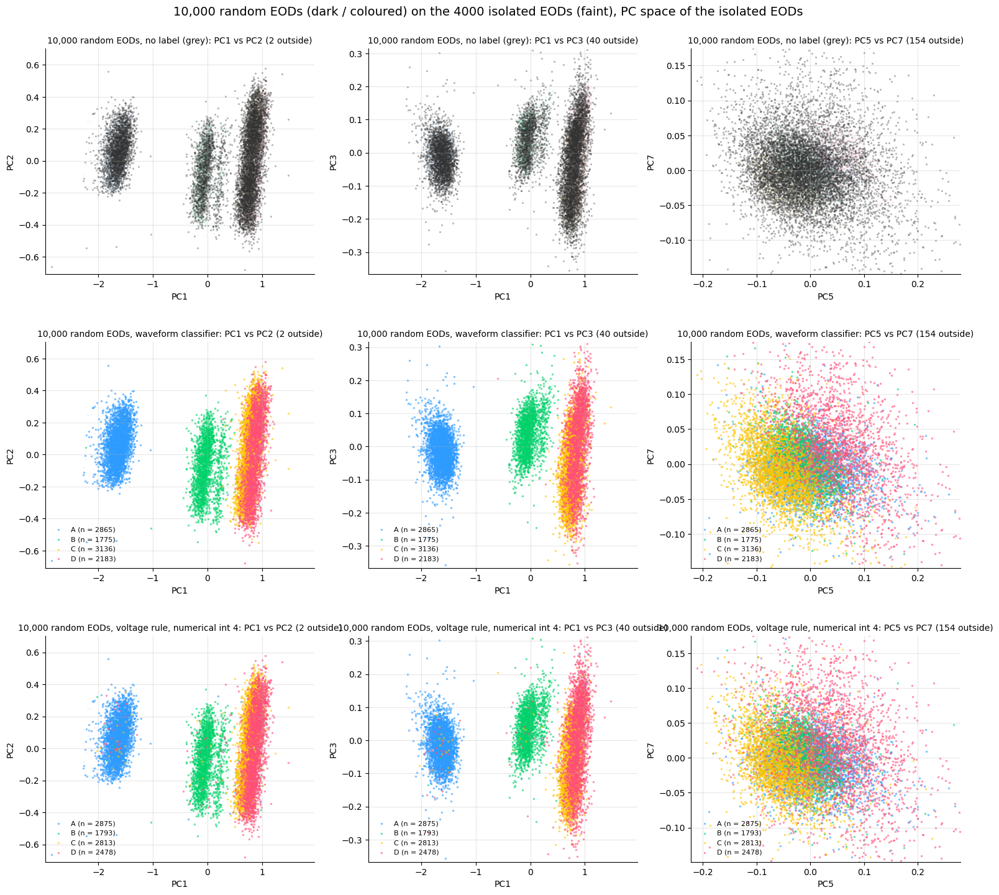

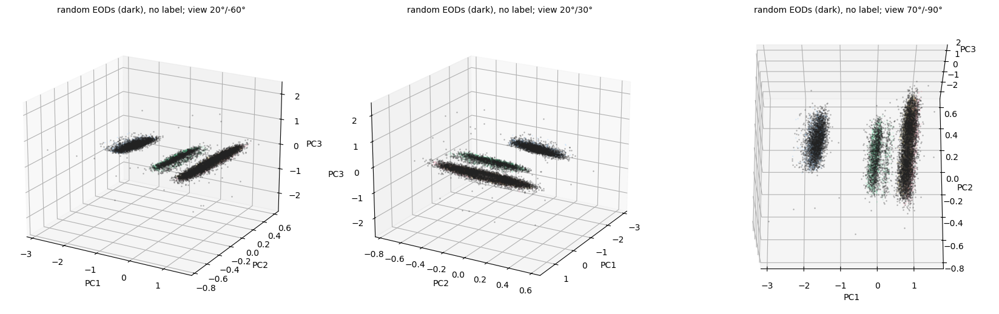

In [16]:
fig, axs = plt.subplots(3, 3, figsize=(19, 17), gridspec_kw=dict(hspace=0.3, wspace=0.2))
rng = np.random.default_rng(3); order = rng.permutation(len(PC10))
PAIRS2D = [(0, 1), (0, 2), (4, 6)]
for c, (i, j) in enumerate(PAIRS2D):
    for r, (name, cols) in enumerate([('no label (grey)', None), ('waveform classifier', pred3), ('voltage rule, numerical int 4', vp)]):
        a = axs[r, c]
        a.scatter(PC10[order, i], PC10[order, j], s=3, c=[COL[f] for f in fish[order]], alpha=0.12, linewidths=0)
        if cols is None: a.scatter(PC3_10[OK3, i], PC3_10[OK3, j], s=5, color='#333', alpha=0.35, linewidths=0)
        else:
            for f in FISH:
                m = OK3 & (cols == f); a.scatter(PC3_10[m, i], PC3_10[m, j], s=6, color=COL[f], alpha=0.6, linewidths=0, label=f'{f} (n = {m.sum()})')
            m = OK3 & (cols == ''); a.scatter(PC3_10[m, i], PC3_10[m, j], s=12, color='#999', label=f'no pick (n = {m.sum()})') if m.any() else None
            a.legend(frameon=False, fontsize=8, loc='lower left')
        lim = [np.percentile(PC10[:, q], [0.1, 99.9]) for q in (i, j)]; pad = [0.25 * (l[1] - l[0]) for l in lim]
        a.set_xlim(lim[0][0] - pad[0], lim[0][1] + pad[0]); a.set_ylim(lim[1][0] - pad[1], lim[1][1] + pad[1])
        out = OK3 & ((PC3_10[:, i] < a.get_xlim()[0]) | (PC3_10[:, i] > a.get_xlim()[1]) | (PC3_10[:, j] < a.get_ylim()[0]) | (PC3_10[:, j] > a.get_ylim()[1]))
        a.set(xlabel=f'PC{i + 1}', ylabel=f'PC{j + 1}', title=f'{NR:,} random EODs, {name}: PC{i + 1} vs PC{j + 1} ({out.sum()} outside)'); a.grid(alpha=0.3)
        a.title.set_fontsize(10)
fig.suptitle(f'{NR:,} random EODs (dark / coloured) on the 4000 isolated EODs (faint), PC space of the isolated EODs', y=0.92, fontsize=14)
fig.savefig(f'{OUT}/random_eods_pc_scatter.png', dpi=110, bbox_inches='tight'); plt.show()

fig = plt.figure(figsize=(21, 7))
for c, (el, az) in enumerate(VIEWS):
    ax = fig.add_subplot(1, 3, c + 1, projection='3d')
    scatter3(ax, PC10[order][:, :3], [COL[f] for f in fish[order]], 3, 0.12)
    m = OK3 & (np.abs(PC3_10[:, :3]) < 3).all(1)
    scatter3(ax, PC3_10[m][:, :3], '#222', 3, 0.35)
    ax.view_init(el, az); ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3'); ax.set_title(f'random EODs (dark), no label; view {el}°/{az}°', fontsize=10)
fig.savefig(f'{OUT}/random_eods_pca_3d.png', dpi=110, bbox_inches='tight'); plt.show()

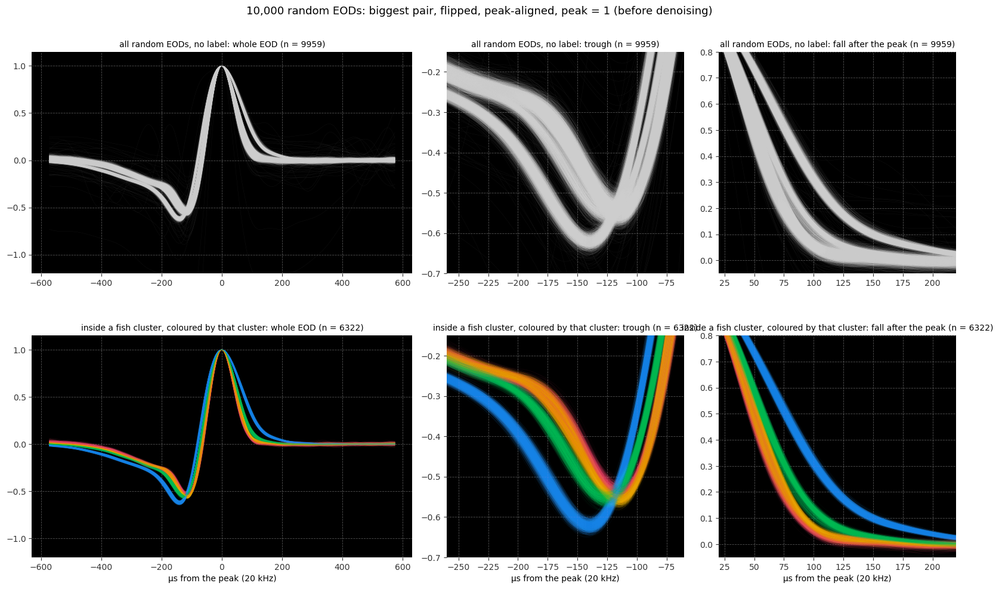

In [17]:
# the waveforms themselves, no label: all random EODs, and only those inside a cluster coloured by that cluster
fig, axs = plt.subplots(2, 3, figsize=(20, 11), gridspec_kw=dict(width_ratios=[1.6, 1, 1], wspace=0.12, hspace=0.28))
for r, (name, sel, colf) in enumerate([('all random EODs, no label', OK3, lambda i: '#E6E6E6'),
                                        ('inside a fish cluster, coloured by that cluster', OK3 & inside, lambda i: COL[nearest[i]])]):
    for a, (zn, xl, yl) in zip(axs[r], ZOOMS):
        sorter_axes(a, f'{name}: {zn} (n = {sel.sum()})'); a.title.set_fontsize(10)
        for i in np.flatnonzero(sel): a.plot(t_us, W3[i], color=colf(i), lw=0.3, alpha=0.08)
        if xl: a.set_xlim(xl); a.set_ylim(yl)
        else: a.set_ylim(-1.2, 1.15)
for a in axs[-1]: a.set_xlabel('µs from the peak (20 kHz)')
fig.suptitle(f'{NR:,} random EODs: biggest pair, flipped, peak-aligned, peak = 1 (before denoising)', y=0.95, fontsize=13)
fig.savefig(f'{OUT}/random_eods_waveforms.png', dpi=110, bbox_inches='tight'); plt.show()